# Rigorous mask diffraction (RCWA) and mask 3D effects

So far the mask has been **thin**: a `ThinMask` multiplies the illumination
by a transmission function, a `FilmMask` uses the transmission of the
absorber film stack for each angle, and an optional `BoundaryLayer` adds
strips at the edges to mimic thick-mask effects. A real absorber is 60–70 nm
thick, and at 4× its mask pitch is only one or two wavelengths. The light
couples into the absorber sidewalls, and the diffraction orders get
amplitudes and phases that the thin models do not have. These are the
**mask 3D effects**: CD offsets, best focus shifts through pitch, and
different behaviour for TE and TM.

`pyoptics.litho.rcwa` solves Maxwell's equations for lamellar gratings with
the **rigorous coupled wave analysis** (RCWA, Fourier modal method):

- the permittivity of each layer is expanded into Fourier series along the
  grating, using Li's factorization rules (the inverse rule for $E_x$),
  which makes TM and metal gratings converge quickly;
- per layer, the modes are the TE and TM modes of the planar problem; any
  direction of incidence is allowed (conical diffraction);
- layers are stacked with the enhanced transmittance matrix method, which
  stays stable for thick and absorbing layers.

`RigorousMask` plugs this into `LithoSimulation` for 1D layouts. Every
source point gets its own orders (Abbe), and `hopkins.TCC` uses the orders
at normal incidence. `calibrate_boundary_layer()` fits the boundary layer
model to the rigorous orders.

Contents:

1. Checks: thin films, energy conservation, convergence.
2. Diffraction orders of a MoSi attenuated PSM: rigorous vs. film mask
   through pitch.
3. Dependence on the angle of incidence, and the Hopkins approximation.
4. Imaging: CD and best focus through pitch, MoSi and chrome.
5. Calibrating the boundary layer model.

ArF immersion: 193 nm, water, NA 1.35, 4× reduction, mask blank
$n = 1.563$.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

from pyoptics.litho import (Illumination, LithoSimulation, MaskLayout, Projector, RigorousMask,
                            hopkins, lens, rcwa)

plt.rcParams.update({"figure.dpi": 100, "font.size": 11})

wl, n_w, NA, M = 193.0, 1.437, 1.35, 4.0
MOSI, CR, BLANK = 2.343 + 0.586j, 0.84 + 1.65j, 1.563  # as in notebook 32
mosi = RigorousMask([(MOSI, 68.0)], name="MoSi 68 nm (6 % att. PSM)")
chrome = RigorousMask([(CR, 70.0)], name="Cr 70 nm (binary)")
projector = Projector(NA, wl, n=n_w)

## 1. Checks

`rcwa.rcwa()` works at mask scale: period, layers (`Layer(thickness,
background, segments)`) and the transverse wave vector of the incident wave
in units of $k_0$. It returns Jones matrices of the reflected and transmitted
orders (tangential $E_x, E_y$). Three checks:

- an unpatterned stack gives the TE/TM transmissions of `thin_films`
  (exact, see the tests);
- a lossless grating conserves energy: the efficiencies of all reflected and
  transmitted orders sum to 1 for any incidence and polarization;
- convergence with the number of orders: Li's factorization against the
  plain Laurent rule for TM light on chrome lines.

k = (+0.0, +0.0): R + T = 0.999999999999997, 1.000000000000001, 0.999999999999999
k = (+0.3, +0.0): R + T = 1.000000000000005, 1.000000000000001, 1.000000000000003
k = (-0.5, +0.7): R + T = 0.999999999999994, 1.000000000000003, 0.999999999999998


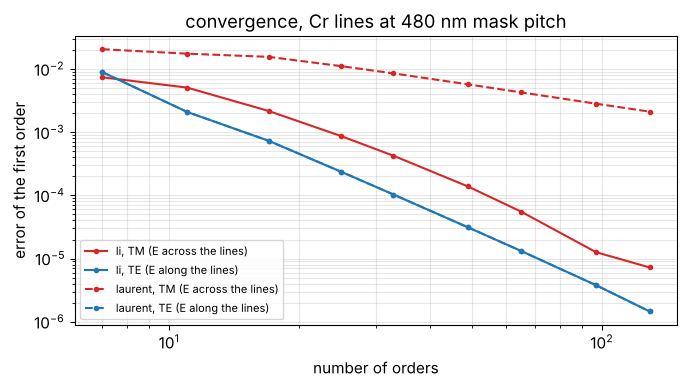

In [2]:
grating = [rcwa.Layer(120.0, 1.0, [(0.0, 250.0, 1.5)]), rcwa.Layer(50.0, 1.3, [(100.0, 100.0, 2.0)])]
for k_x, k_y in ((0.0, 0.0), (0.3, 0.0), (-0.5, 0.7)):
    res = rcwa.rcwa(500.0, grating, wl, k_x, k_y, n_in=BLANK, n_out=1.0, n_orders=15)
    sums = [sum(e.sum() for e in res.efficiencies(j)) for j in ([1, 0], [0, 1], [1, 1j])]
    print(f"k = ({k_x:+.1f}, {k_y:+.1f}): R + T = " + ", ".join(f"{s:.15f}" for s in sums))

cr_lines = [rcwa.Layer(70.0, 1.0, [(0.0, 240.0, CR)])]  # 60 nm lines at 120 nm pitch (wafer scale)
orders = np.array([3, 5, 8, 12, 16, 24, 32, 48, 64])
ref = {pol: rcwa.rcwa(480.0, cr_lines, wl, 0.1, 0.0, n_in=BLANK, n_orders=120).t[0, 121, pol, pol]
       for pol in (0, 1)}
fig, ax = plt.subplots(figsize=(7, 4))
for fac, ls in (("li", "-"), ("laurent", "--")):
    for pol, c, name in ((0, "C3", "TM (E across the lines)"), (1, "C0", "TE (E along the lines)")):
        err = [abs(rcwa.rcwa(480.0, cr_lines, wl, 0.1, 0.0, n_in=BLANK, n_orders=k,
                             factorization=fac).t[0, k + 1, pol, pol] - ref[pol]) for k in orders]
        ax.loglog(2*orders + 1, err, ls, color=c, marker="o", ms=3, label=f"{fac}, {name}")
ax.set_xlabel("number of orders"); ax.set_ylabel("error of the first order")
ax.set_title("convergence, Cr lines at 480 nm mask pitch"); ax.legend(fontsize=8); ax.grid(alpha=0.3, which="both")
plt.tight_layout()

For TE both rules are the same. For TM, Laurent's rule converges slowly;
Li's inverse rule is about an order of magnitude better. (For TE the two
curves lie on top of each other.) `RigorousMask`
keeps roughly twice as many orders as propagate in the blank (at least
21), which gives about $10^{-3}$ accuracy on the orders that reach the
pupil.

## 2. Diffraction orders through pitch

At normal incidence, lines and spaces with a 1:1 duty cycle on a MoSi
attenuated PSM. Thin (film) mask: the orders are the Fourier coefficients
of the transmission, independent of polarization, and they scale with
pitch. Rigorous: TE and TM orders differ, and their amplitudes and phases
change with pitch. The phase of the first order relative to the zeroth
acts like a defocus term in the pupil: it shifts best focus differently for
each pitch.

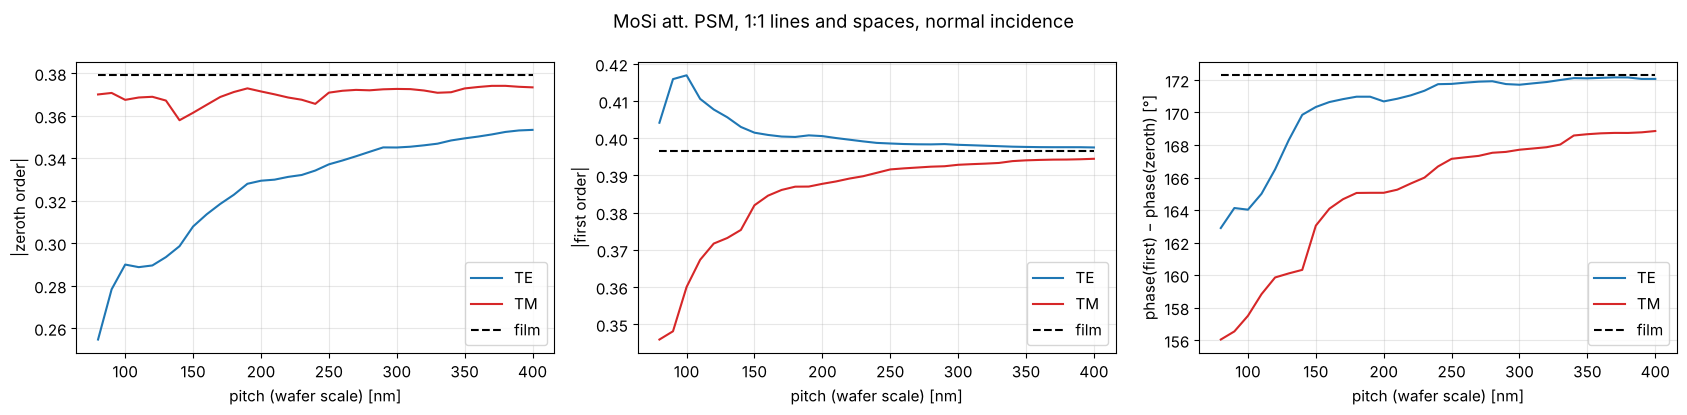

In [3]:
pitches = np.linspace(80, 400, 33)
zero = np.zeros(1)
film = mosi.film_mask()
J_abs = film.jones(zero, zero, NA, wl, M)[1][0][0, 0]
a = {"TM": [], "TE": [], "film": []}
for p in pitches:
    layout = MaskLayout.lines_spaces(p, p/2)
    J_o = mosi.order_jones(layout, np.arange(-1, 2), [0], zero, zero, NA, wl, M)[0][:, :, 0]
    a["TM"].append(J_o[0, 0]); a["TE"].append(J_o[1, 1])
    c = layout.region_coefficients(np.arange(-1, 2), [0])
    a["film"].append(c["field"][0] + c["feature"][0]*J_abs)
a = {k: np.array(v) for k, v in a.items()}

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
styles = {"TE": ("C0", "-"), "TM": ("C3", "-"), "film": ("k", "--")}
for k, (c, ls) in styles.items():
    axes[0].plot(pitches, np.abs(a[k][:, 1]), ls, color=c, label=k)
    axes[1].plot(pitches, np.abs(a[k][:, 2]), ls, color=c, label=k)
    dphi = np.degrees(np.angle(a[k][:, 2]/a[k][:, 1]))
    axes[2].plot(pitches, dphi, ls, color=c, label=k)
axes[0].set_ylabel("|zeroth order|"); axes[1].set_ylabel("|first order|")
axes[2].set_ylabel("phase(first) − phase(zeroth) [°]")
for ax in axes:
    ax.set_xlabel("pitch (wafer scale) [nm]"); ax.legend(); ax.grid(alpha=0.3)
fig.suptitle("MoSi att. PSM, 1:1 lines and spaces, normal incidence")
plt.tight_layout()

The rigorous orders converge towards the film mask at large pitches. At
small pitches the zeroth order (the background) drops in TE, and the
first order is stronger in TE and weaker in TM than the film model
predicts. The phase difference between the orders is about 172° for the
film mask (the MoSi phase at 68 nm; 180° needs a thicker film). In the
rigorous mask it drops by up to 16° at small pitches, more in TM. A pupil
phase between the orders acts like defocus for that pitch.

## 3. Angle of incidence and the Hopkins approximation

Each source point illuminates the mask at its own angle: $\sin\theta =
\mathrm{NA}\,s/M$ in air, up to about 0.34. A thin mask diffracts the same
orders for every angle (shifted in the pupil). A thick absorber does not:
its order amplitudes depend on the angle, by different amounts for each
order. The Hopkins TCC assumes normal incidence for all source points;
Abbe with `RigorousMask` recomputes the orders for each one.

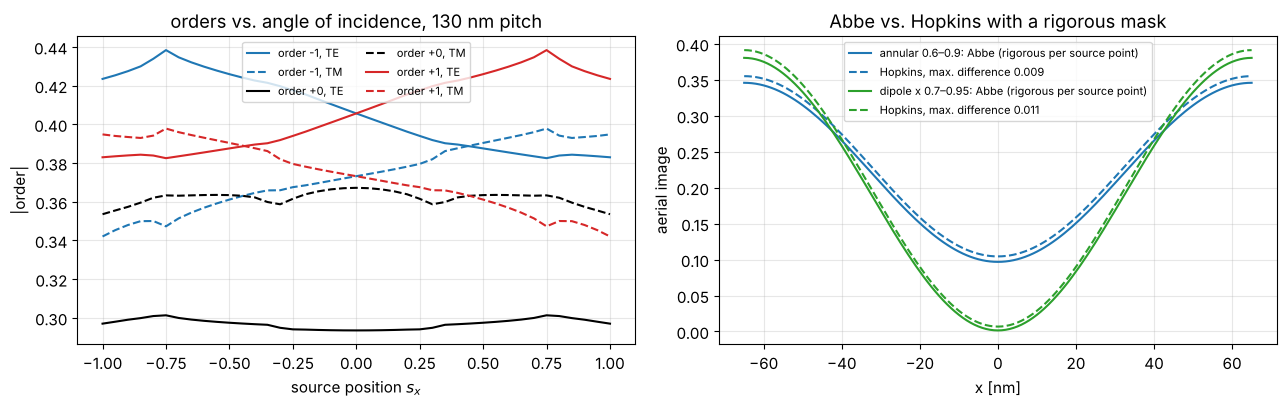

In [4]:
layout = MaskLayout.lines_spaces(130.0, 65.0)
s = np.linspace(-1, 1, 41)
J_o = mosi.order_jones(layout, np.arange(-1, 2), [0], s, np.zeros_like(s), NA, wl, M)[:, :, :, 0]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for i, (m, c) in enumerate(((-1, "C0"), (0, "k"), (1, "C3"))):
    axes[0].plot(s, np.abs(J_o[:, 1, 1, i]), color=c, label=f"order {m:+d}, TE")
    axes[0].plot(s, np.abs(J_o[:, 0, 0, i]), "--", color=c, label=f"order {m:+d}, TM")
axes[0].set_xlabel("source position $s_x$"); axes[0].set_ylabel("|order|")
axes[0].set_title("orders vs. angle of incidence, 130 nm pitch"); axes[0].legend(fontsize=8, ncol=2)

x = np.linspace(-65, 65, 131)
for ill, c in ((Illumination.annular(0.9, 0.6, n_samples=15, polarization="TE"), "C0"),
               (Illumination.dipole(0.95, 0.7, n_samples=15, polarization="y"), "C2")):
    sim = LithoSimulation(layout, mosi, ill, projector)
    I_abbe, I_hop = sim.image(x), hopkins.TCC(sim).image(x)[0]
    axes[1].plot(x, I_abbe, color=c, label=f"{ill.name}: Abbe (rigorous per source point)")
    axes[1].plot(x, I_hop, "--", color=c, label=f"Hopkins, max. difference {np.abs(I_hop - I_abbe).max():.3f}")
axes[1].set_xlabel("x [nm]"); axes[1].set_ylabel("aerial image"); axes[1].legend(fontsize=8)
axes[1].set_title("Abbe vs. Hopkins with a rigorous mask")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()

The ±1st orders change by several percent across the source and in
opposite directions. Their imbalance across the source acts like a
telecentricity error from the mask and tilts the Bossung curves. The
Hopkins approximation is good to about a percent of the clear-field
intensity here. That is fine for screening; CD-level work needs Abbe.

## 4. Imaging through pitch

CD at a fixed threshold, and best focus (the vertex of NILS through focus,
as in notebook 33), for the rigorous masks and their film approximations.
TE-polarized annular illumination.

7.6 s


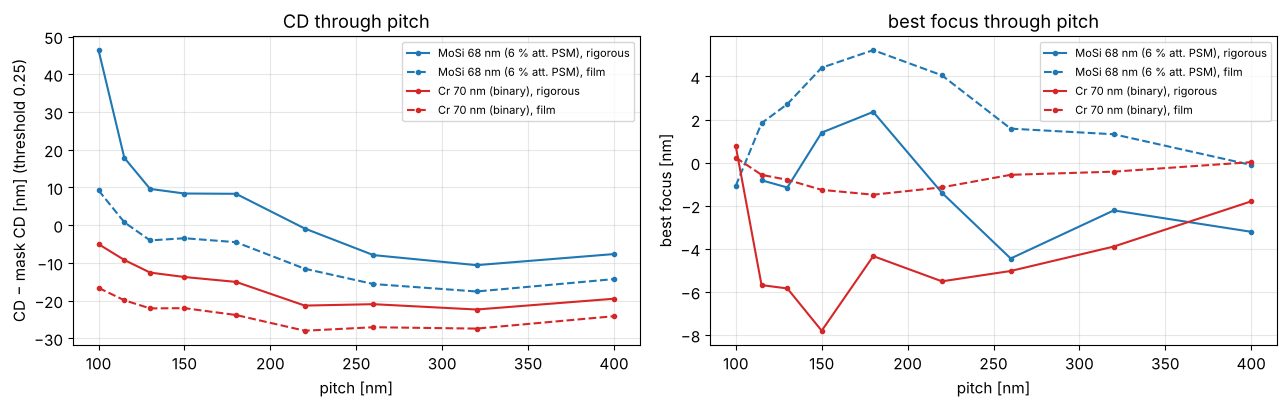

In [5]:
ill = Illumination.annular(0.9, 0.6, n_samples=15, polarization="TE")
pitches_img = np.array([100, 115, 130, 150, 180, 220, 260, 320, 400])
foci = np.linspace(-80, 80, 9)
results = {}
t0 = time.time()
for rig in (mosi, chrome):
    for stack, kind in ((rig, "rigorous"), (rig.film_mask(), "film")):
        r = [lens.feature_response(LithoSimulation(MaskLayout.lines_spaces(p, p/2), stack, ill, projector),
                                   threshold=0.25, foci=foci) for p in pitches_img]
        results[rig.name, kind] = (np.array([x.cd for x in r]), np.array([x.best_focus for x in r]))
print(f"{time.time() - t0:.1f} s")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for rig, c in ((mosi, "C0"), (chrome, "C3")):
    for kind, ls in (("rigorous", "-"), ("film", "--")):
        cd, bf = results[rig.name, kind]
        axes[0].plot(pitches_img, cd - pitches_img/2, ls, marker="o", ms=3, color=c, label=f"{rig.name}, {kind}")
        axes[1].plot(pitches_img, bf, ls, marker="o", ms=3, color=c, label=f"{rig.name}, {kind}")
axes[0].set_ylabel("CD − mask CD [nm] (threshold 0.25)"); axes[0].set_title("CD through pitch")
axes[1].set_ylabel("best focus [nm]"); axes[1].set_title("best focus through pitch")
for ax in axes:
    ax.set_xlabel("pitch [nm]"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout()

The rigorous lines print wider than the film model predicts: by 5 to 10 nm
for chrome, and by 7 nm at large pitches up to 37 nm at 100 nm pitch for
MoSi. The thick absorber edges block more light than a thin absorber of
the same width. This is a mask bias that OPC has to correct, and it
depends on the material. Best focus through pitch also differs between
the two models, by several nanometres (up to 8 nm for chrome). These are
the effects that thin mask models must be calibrated for.

## 5. Calibrating the boundary layer model

The boundary layer model puts strips of width $w$ with transmissions
$t_\mathrm{TE}$ and $t_\mathrm{TM}$ on every edge. For a given $w$ the
orders are linear in the two transmissions, so `calibrate_boundary_layer()`
fits them by least squares to the rigorous orders of a set of layouts at
normal incidence and scans $w$. The calibrated `FilmMask` with
`BoundaryLayer` is as fast as the thin models.

MoSi 68 nm (6 % att. PSM): w = 7.5 nm, t_TE = -0.320-0.041j, t_TM = 0.205+0.577j, residual of the orders 6.5 % (film mask alone: 13.3 %)
Cr 70 nm (binary): w = 9.5 nm, t_TE = 0.283-0.443j, t_TM = 0.227+0.249j, residual of the orders 7.7 % (film mask alone: 12.9 %)


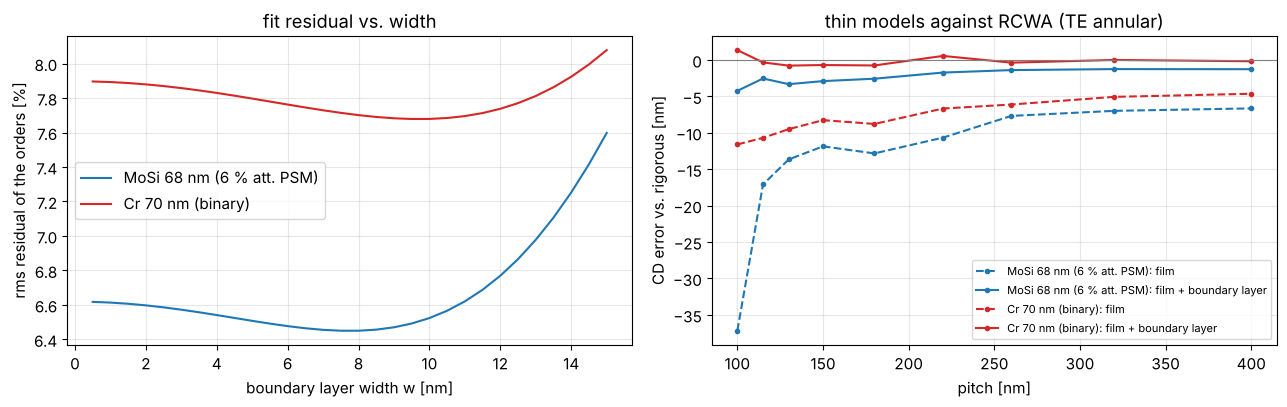

In [6]:
cal_layouts = [MaskLayout.lines_spaces(p, p/2) for p in (100, 130, 180, 260, 400)]
cals = {rig.name: rcwa.calibrate_boundary_layer(rig, cal_layouts, NA, wl, M) for rig in (mosi, chrome)}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for (name, cal), c in zip(cals.items(), ("C0", "C3")):
    bl = cal.boundary_layer
    print(f"{name}: w = {bl.width:.1f} nm, t_TE = {bl.t_TE:.3f}, t_TM = {bl.t_TM:.3f}, "
          f"residual of the orders {100*cal.residual.min():.1f} % "
          f"(film mask alone: {100*cal.residual_base:.1f} %)")
    axes[0].plot(cal.widths, 100*cal.residual, color=c, label=name)

for rig, c in ((mosi, "C0"), (chrome, "C3")):
    cd_rig = results[rig.name, "rigorous"][0]
    cd_film = results[rig.name, "film"][0]
    cd_bl = np.array([LithoSimulation(MaskLayout.lines_spaces(p, p/2), cals[rig.name].stack, ill, projector)
                      .cd(0.25) for p in pitches_img])
    axes[1].plot(pitches_img, cd_film - cd_rig, "--", marker="o", ms=3, color=c, label=f"{rig.name}: film")
    axes[1].plot(pitches_img, cd_bl - cd_rig, "-", marker="o", ms=3, color=c, label=f"{rig.name}: film + boundary layer")
axes[0].set_xlabel("boundary layer width w [nm]"); axes[0].set_ylabel("rms residual of the orders [%]")
axes[0].set_title("fit residual vs. width"); axes[0].legend()
axes[1].axhline(0, color="gray", lw=0.8)
axes[1].set_xlabel("pitch [nm]"); axes[1].set_ylabel("CD error vs. rigorous [nm]")
axes[1].set_title("thin models against RCWA (TE annular)"); axes[1].legend(fontsize=8)
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()

The calibrated boundary layer brings the CD through pitch to within 1 to
4 nm of the rigorous result, against 5 to 37 nm for the film mask alone.
It needs only one width and two complex transmissions per material. The
fit depends little on the width: narrow strips with stronger
transmissions do about as well as wide ones. What remains comes from what
a boundary layer cannot represent: the angle dependence of section 3 (the
calibration is at normal incidence) and the coupling between neighbouring
edges at the smallest pitches.

## Summary

- `rcwa.rcwa()`: RCWA of lamellar gratings with Li's factorization,
  conical incidence and stable stacking; exact for unpatterned stacks and
  energy-conserving for lossless gratings.
- `RigorousMask`: a mask stack for 1D layouts in `LithoSimulation` (orders
  per source point) and `hopkins.TCC` (orders at normal incidence).
- Mask 3D effects: polarization-dependent order amplitudes, phase errors
  between the orders, angle dependence, CD offsets of tens of nanometres
  and best focus shifts through pitch that thin masks miss.
- `calibrate_boundary_layer()` turns RCWA into a fast, calibrated thin
  mask model.
- Limitations: 1D layouts only (no contact holes), and the Hopkins
  approximation for the TCC.